# 06 — Análise de Entregas
**Olist Analytics Hub | Etapa 6 de 7**

**Objetivo:** Medir o desempenho logístico — prazo real, prazo prometido e atraso — e testar se o atraso na entrega realmente derruba a avaliação do cliente.

---
### Perguntas que este notebook responde
1. Quanto tempo leva uma entrega e quanto o prazo prometido é folgado?
2. Quais estados recebem mais rápido e quais sofrem mais atraso?
3. A pontualidade mudou ao longo do tempo?
4. O atraso derruba a nota? Quanto?

In [1]:
import sys
sys.path.insert(0, '..')

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.ticker as mticker
import seaborn as sns
from scipy import stats
from IPython.display import display

from src.data_cleaner import load_processed, save_processed
from src.visualizations import setup_style, save_fig, format_brl
from src.config import COLORS

setup_style()
pd.set_option('display.max_columns', None)
pd.set_option('display.float_format', lambda x: f'{x:,.2f}')

print('✓ Ambiente configurado.')

✓ Ambiente configurado.


In [2]:
df = load_processed('orders_enriched')

# Pedidos entregues e com data de entrega registrada (8 pedidos "delivered" não têm a data)
entregas = df[df['is_delivered'] & df['delivery_days'].notna()].copy()
entregas['atrasado'] = entregas['delivery_delay_days'] > 0

print(f'Pedidos analisados: {len(entregas):,}')
print(f'Prazo real (mediana): {entregas["delivery_days"].median():.0f} dias')
print(f'Prazo prometido (mediana): {entregas["days_to_estimated"].median():.0f} dias')
print(f'Entregues no prazo: {entregas["delivered_on_time"].mean():.1%}')
print(f'Entregues com atraso: {entregas["atrasado"].sum():,} ({entregas["atrasado"].mean():.1%})')

Pedidos analisados: 96,470
Prazo real (mediana): 10 dias
Prazo prometido (mediana): 23 dias
Entregues no prazo: 92.4%
Entregues com atraso: 7,307 (7.6%)


## 1. Prazo Real × Prazo Prometido

  ✓ Figura salva: 06_prazo_real_prometido.png


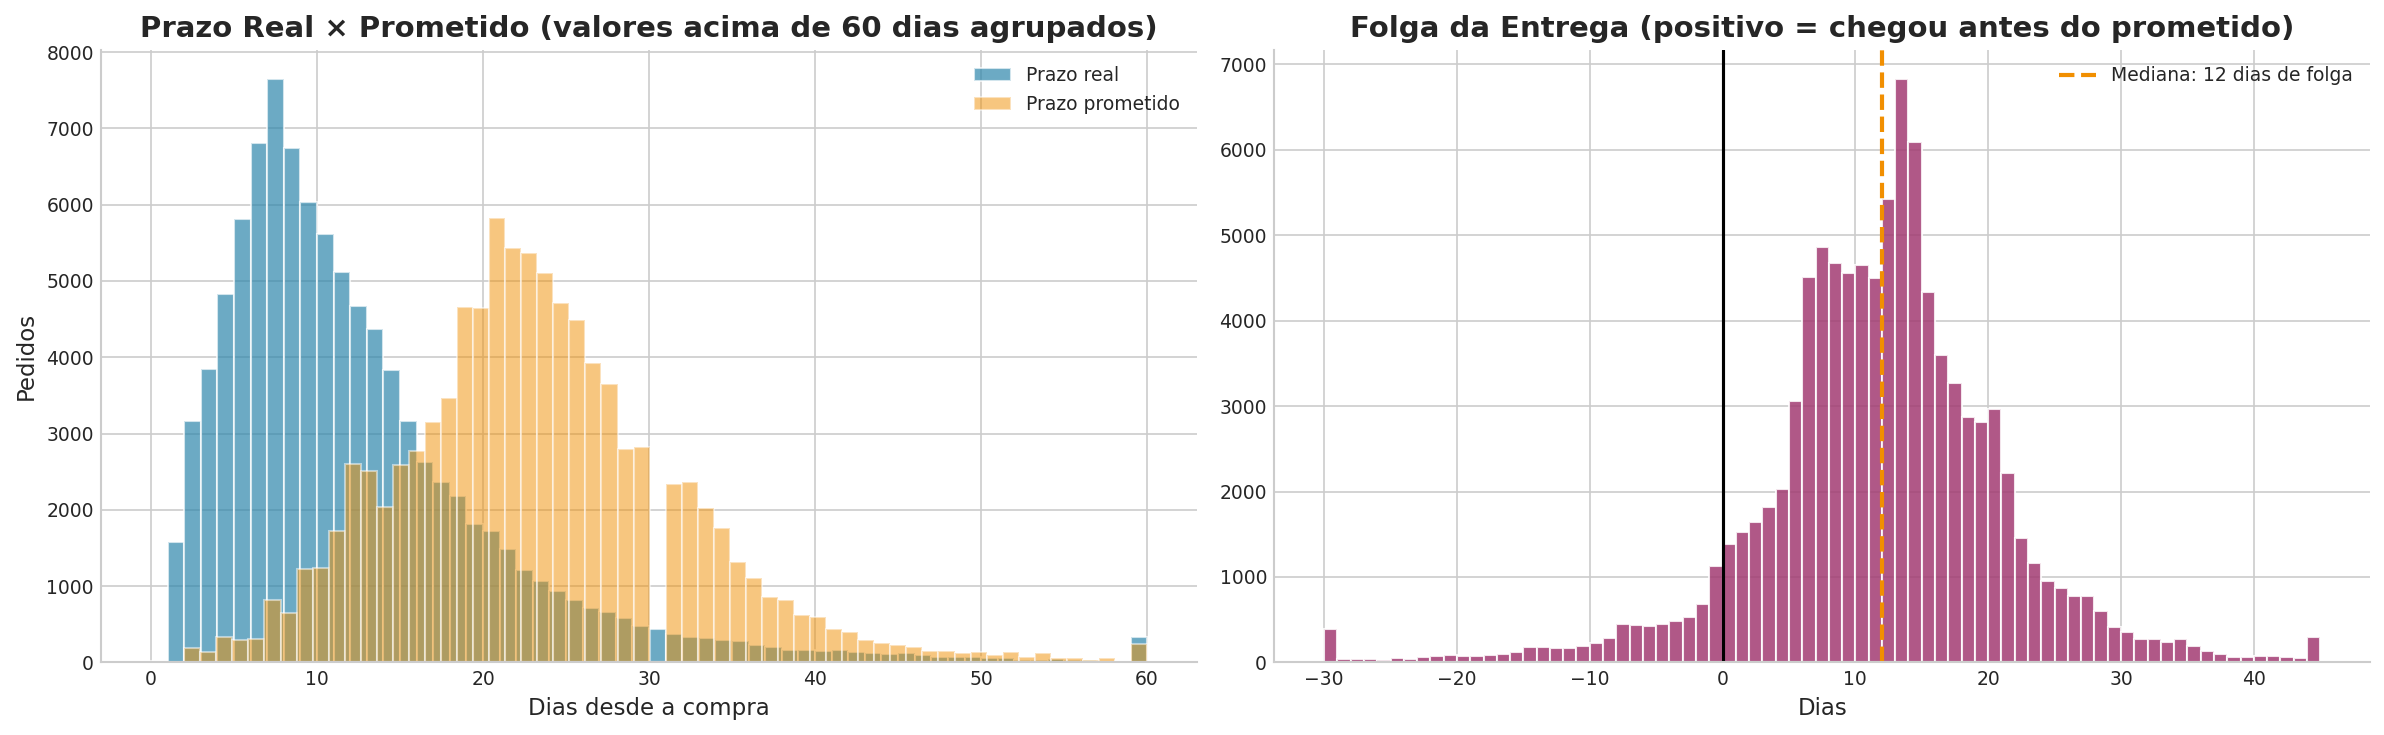

In [3]:
fig, axes = plt.subplots(1, 2, figsize=(16, 5))

limite = 60
axes[0].hist(entregas['delivery_days'].clip(upper=limite), bins=60, alpha=0.7,
             color=COLORS['primary'], label='Prazo real', edgecolor='white')
axes[0].hist(entregas['days_to_estimated'].clip(upper=limite), bins=60, alpha=0.5,
             color=COLORS['accent'], label='Prazo prometido', edgecolor='white')
axes[0].set_title(f'Prazo Real × Prometido (valores acima de {limite} dias agrupados)')
axes[0].set_xlabel('Dias desde a compra')
axes[0].set_ylabel('Pedidos')
axes[0].legend()

folga = -entregas['delivery_delay_days']
axes[1].hist(folga.clip(-30, 45), bins=75, color=COLORS['secondary'], alpha=0.85, edgecolor='white')
axes[1].axvline(0, color='black', linewidth=1.5)
axes[1].axvline(folga.median(), color=COLORS['accent'], linestyle='--', linewidth=2,
                label=f'Mediana: {folga.median():.0f} dias de folga')
axes[1].set_title('Folga da Entrega (positivo = chegou antes do prometido)')
axes[1].set_xlabel('Dias')
axes[1].legend()

plt.tight_layout()
save_fig('06_prazo_real_prometido')
plt.show()

## 2. Desempenho por Estado

In [4]:
por_estado = (
    entregas
    .groupby('customer_state')
    .agg(
        pedidos=('order_id', 'count'),
        prazo_real_mediano=('delivery_days', 'median'),
        prazo_prometido_mediano=('days_to_estimated', 'median'),
        taxa_no_prazo=('delivered_on_time', 'mean'),
        frete_medio=('freight', 'mean'),
        nota_media=('review_score', 'mean'),
    )
    .sort_values('prazo_real_mediano')
)
por_estado['taxa_no_prazo'] *= 100

display(
    por_estado
    .style
    .format({'pedidos': '{:,.0f}', 'prazo_real_mediano': '{:.0f} d', 'prazo_prometido_mediano': '{:.0f} d',
             'taxa_no_prazo': '{:.1f}%', 'frete_medio': 'R$ {:,.2f}', 'nota_media': '{:.2f}'})
    .background_gradient(subset=['taxa_no_prazo'], cmap='RdYlGn')
    .background_gradient(subset=['prazo_real_mediano'], cmap='Reds')
)

,pedidos,prazo_real_mediano,prazo_prometido_mediano,taxa_no_prazo,frete_medio,nota_media
customer_state,,,,,,
SP,"40,494",7 d,18 d,94.7%,R$ 17.33,4.25
PR,"4,923",10 d,24 d,95.4%,R$ 23.49,4.24
MG,"11,354",10 d,23 d,94.8%,R$ 23.46,4.19
DF,"2,080",11 d,24 d,93.4%,R$ 23.86,4.13
RJ,"12,350",12 d,24 d,87.1%,R$ 23.95,3.97
MS,701,13 d,25 d,89.0%,R$ 27.02,4.16
ES,"1,995",13 d,25 d,88.2%,R$ 24.57,4.08
GO,"1,957",13 d,26 d,92.5%,R$ 26.25,4.11
RS,"5,344",13 d,28 d,93.4%,R$ 24.81,4.18


  ✓ Figura salva: 06_entregas_por_estado.png


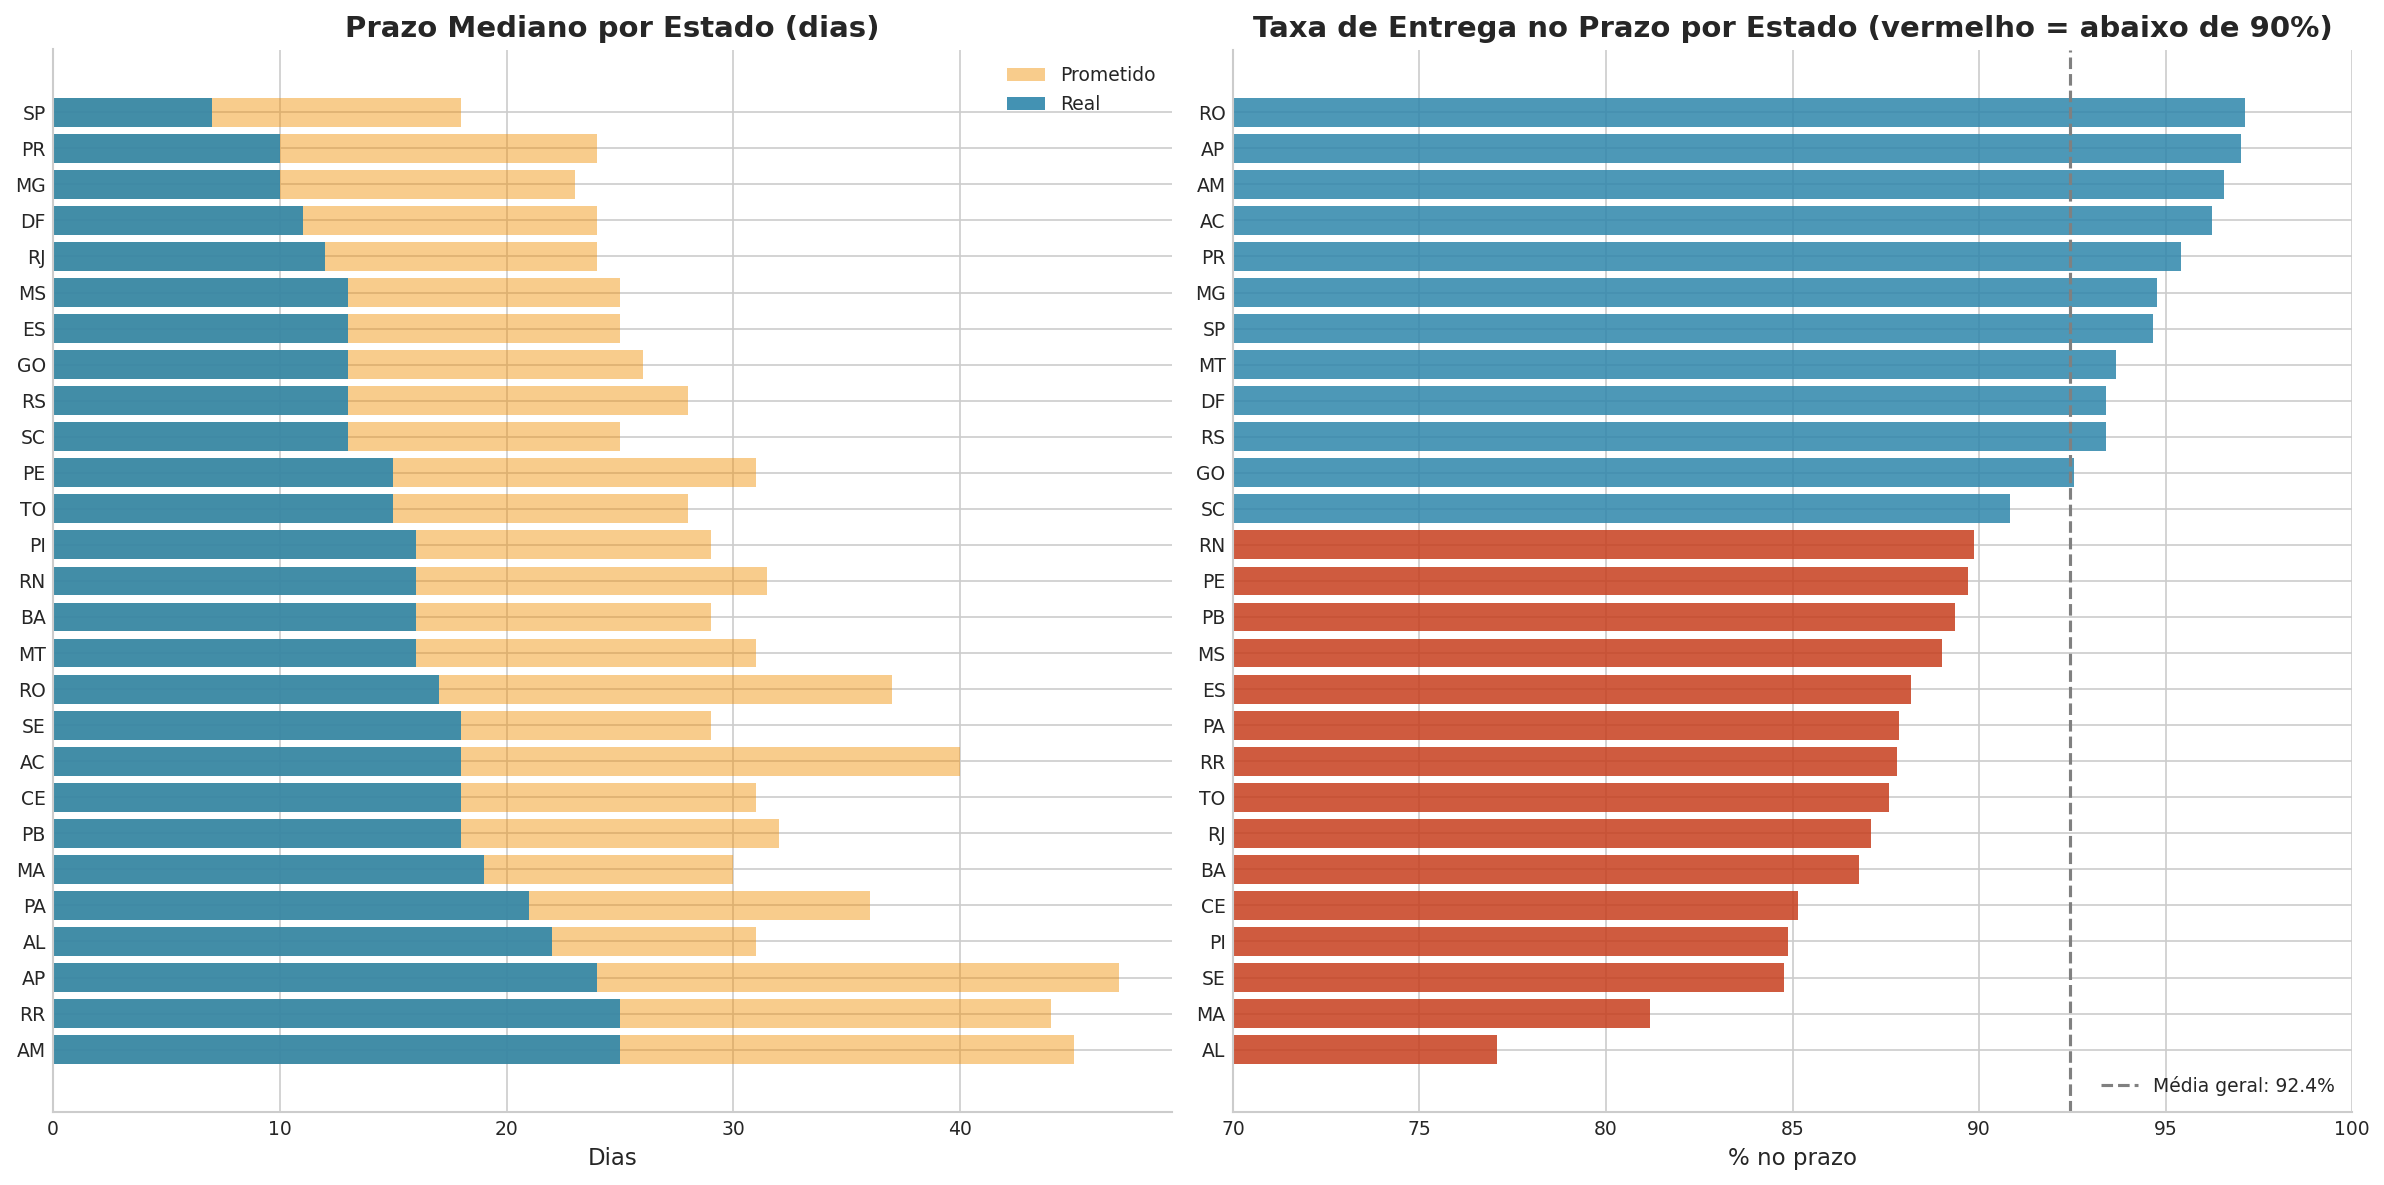

In [5]:
fig, axes = plt.subplots(1, 2, figsize=(16, 8))

pe = por_estado.reset_index()
axes[0].barh(pe['customer_state'], pe['prazo_prometido_mediano'], color=COLORS['accent'], alpha=0.45, label='Prometido')
axes[0].barh(pe['customer_state'], pe['prazo_real_mediano'], color=COLORS['primary'], alpha=0.9, label='Real')
axes[0].invert_yaxis()
axes[0].set_title('Prazo Mediano por Estado (dias)')
axes[0].set_xlabel('Dias')
axes[0].legend()

pe_taxa = por_estado.sort_values('taxa_no_prazo').reset_index()
cores = [COLORS['success'] if t < 90 else COLORS['primary'] for t in pe_taxa['taxa_no_prazo']]
axes[1].barh(pe_taxa['customer_state'], pe_taxa['taxa_no_prazo'], color=cores, alpha=0.85)
axes[1].axvline(entregas['delivered_on_time'].mean() * 100, color='gray', linestyle='--', linewidth=1.5,
                label=f'Média geral: {entregas["delivered_on_time"].mean():.1%}')
axes[1].set_xlim(70, 100)
axes[1].set_title('Taxa de Entrega no Prazo por Estado (vermelho = abaixo de 90%)')
axes[1].set_xlabel('% no prazo')
axes[1].legend(loc='lower right')

plt.tight_layout()
save_fig('06_entregas_por_estado')
plt.show()

O prazo prometido cresce junto com o prazo real — a Olist já embute a distância na estimativa. Por isso estados distantes, como AM e AP, têm entregas lentas e mesmo assim boa pontualidade. Os piores em pontualidade são estados do Nordeste (AL, MA) e, entre os grandes mercados, o RJ.

## 3. Pontualidade ao Longo do Tempo

  ✓ Figura salva: 06_pontualidade_mensal.png


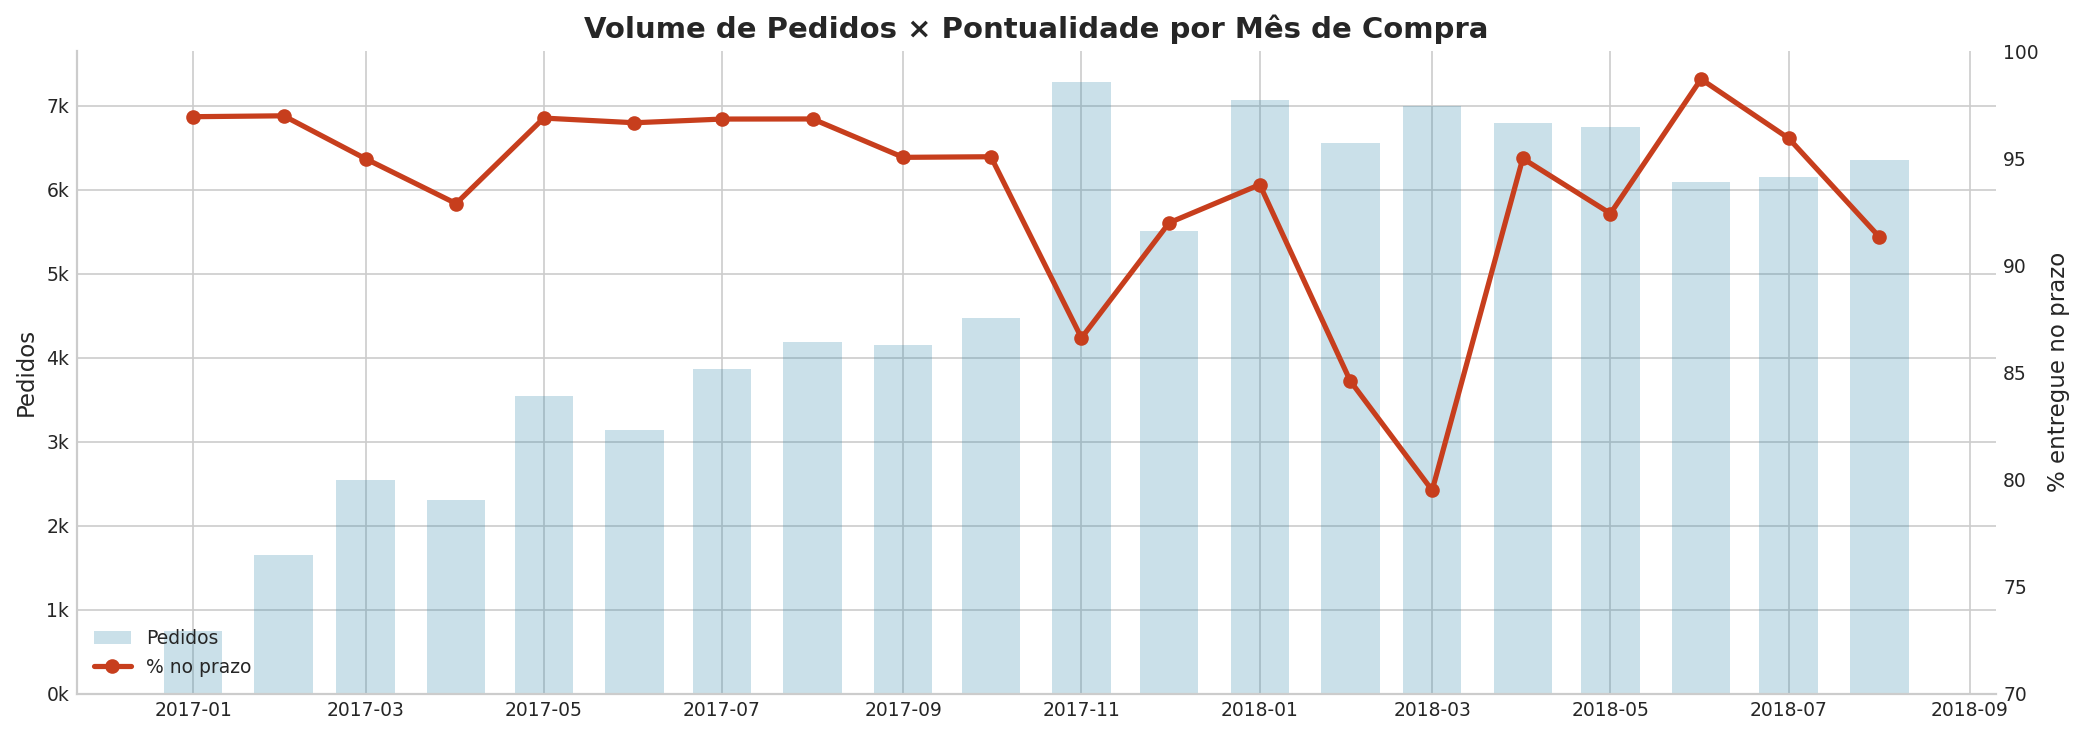

Mar/2018: 79.5% no prazo (7,003 pedidos)
Feb/2018: 84.6% no prazo (6,555 pedidos)
Nov/2017: 86.6% no prazo (7,288 pedidos)


In [6]:
mensal = (
    entregas
    .groupby(entregas['order_purchase_timestamp'].dt.to_period('M'))
    .agg(pedidos=('order_id', 'count'), taxa_no_prazo=('delivered_on_time', 'mean'))
    .reset_index()
)
mensal['mes'] = mensal['order_purchase_timestamp'].dt.to_timestamp()
mensal = mensal[mensal['mes'] >= '2017-01-01']

fig, ax1 = plt.subplots(figsize=(14, 5))
ax1.bar(mensal['mes'], mensal['pedidos'], width=20, color=COLORS['primary'], alpha=0.25, label='Pedidos')
ax1.set_ylabel('Pedidos')
ax1.yaxis.set_major_formatter(mticker.FuncFormatter(lambda x, _: f'{x/1e3:.0f}k'))

ax2 = ax1.twinx()
ax2.plot(mensal['mes'], mensal['taxa_no_prazo'] * 100, color=COLORS['success'], linewidth=2.5, marker='o', label='% no prazo')
ax2.set_ylabel('% entregue no prazo')
ax2.set_ylim(70, 100)
ax2.grid(False)

ax1.set_title('Volume de Pedidos × Pontualidade por Mês de Compra')
linhas = ax1.get_legend_handles_labels()[0] + ax2.get_legend_handles_labels()[0]
rotulos = ax1.get_legend_handles_labels()[1] + ax2.get_legend_handles_labels()[1]
ax1.legend(linhas, rotulos, loc='lower left')
plt.tight_layout()
save_fig('06_pontualidade_mensal')
plt.show()

for _, row in mensal.nsmallest(3, 'taxa_no_prazo').iterrows():
    print(f'{row["mes"].strftime("%b/%Y")}: {row["taxa_no_prazo"]:.1%} no prazo ({row["pedidos"]:,} pedidos)')

## 4. O Atraso Derruba a Nota?

Aqui está a pergunta principal do notebook. Comparo a nota de quem recebeu no prazo com a de quem recebeu atrasado, e depois olho a nota em faixas de atraso para ver o formato da relação.

In [7]:
avaliados = entregas.dropna(subset=['review_score']).copy()

comparacao = (
    avaliados
    .groupby('atrasado')
    .agg(
        pedidos=('order_id', 'count'),
        nota_media=('review_score', 'mean'),
        pct_nota_1_2=('review_score', lambda s: (s <= 2).mean() * 100),
        pct_nota_5=('review_score', lambda s: (s == 5).mean() * 100),
    )
    .rename(index={False: 'No prazo', True: 'Atrasado'})
)
display(comparacao.round(2))

# Teste de hipótese: as notas não seguem distribuição normal (escala 1-5), então uso Mann-Whitney
no_prazo = avaliados.loc[~avaliados['atrasado'], 'review_score']
atrasado = avaliados.loc[avaliados['atrasado'], 'review_score']
mw = stats.mannwhitneyu(atrasado, no_prazo, alternative='less')
spearman = stats.spearmanr(avaliados['delivery_delay_days'], avaliados['review_score'])

print(f'Mann-Whitney (atrasado < no prazo): p-valor = {mw.pvalue:.2e}')
print(f'Correlação de Spearman (atraso × nota): {spearman.statistic:.3f} (p-valor = {spearman.pvalue:.2e})')

,pedidos,nota_media,pct_nota_1_2,pct_nota_5
atrasado,,,,
No prazo,88677,4.29,9.24,62.37
Atrasado,7147,2.46,57.06,20.18


Mann-Whitney (atrasado < no prazo): p-valor = 0.00e+00
Correlação de Spearman (atraso × nota): -0.176 (p-valor = 0.00e+00)


In [8]:
faixas = [-np.inf, -15, -8, -1, 0, 3, 7, 14, np.inf]
rotulos_faixas = ['15+ dias antes', '8–14 antes', '1–7 antes', 'No dia', '1–3 atraso', '4–7 atraso', '8–14 atraso', '15+ atraso']
avaliados['faixa_atraso'] = pd.cut(avaliados['delivery_delay_days'], bins=faixas, labels=rotulos_faixas)

por_faixa = (
    avaliados
    .groupby('faixa_atraso', observed=True)
    .agg(pedidos=('order_id', 'count'), nota_media=('review_score', 'mean'))
)
display(por_faixa.round(2))

,pedidos,nota_media
faixa_atraso,,
15+ dias antes,31445,4.32
8–14 antes,36520,4.32
1–7 antes,19343,4.21
No dia,1369,4.12
1–3 atraso,2330,3.61
4–7 atraso,1747,2.23
8–14 atraso,1630,1.71
15+ atraso,1440,1.71


  ✓ Figura salva: 06_atraso_vs_nota.png


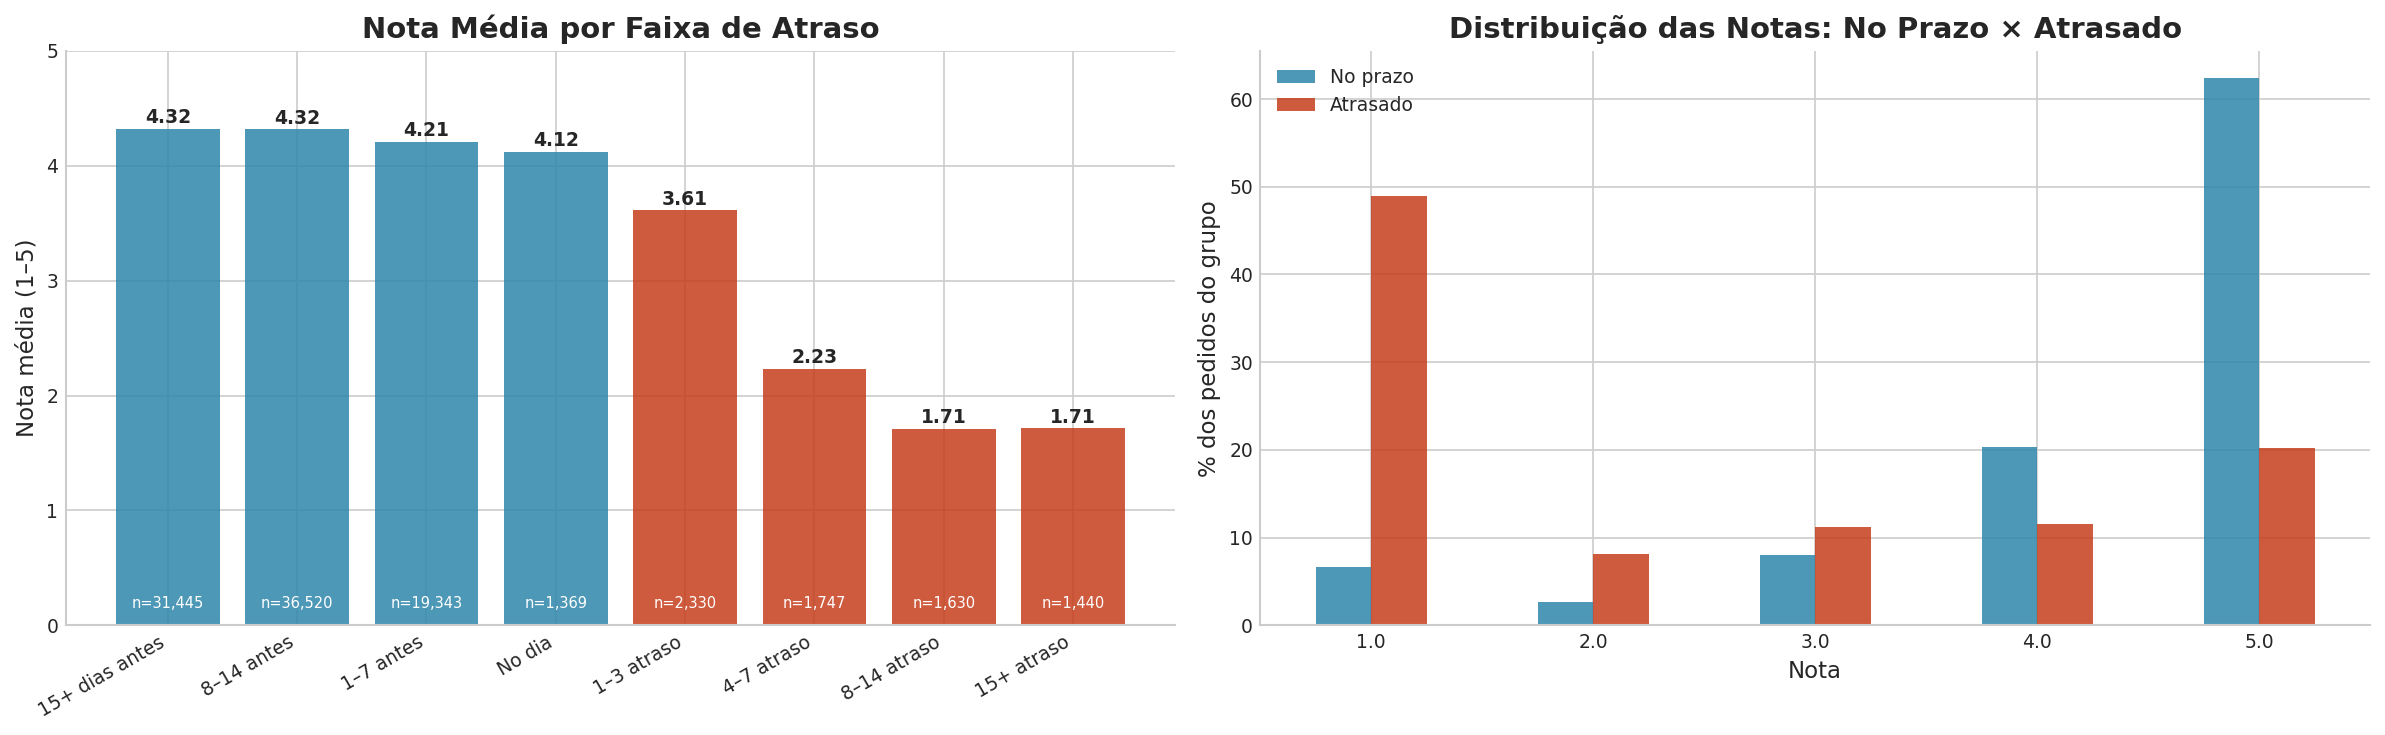

In [9]:
fig, axes = plt.subplots(1, 2, figsize=(16, 5))

cores_faixa = [COLORS['primary']] * 4 + [COLORS['success']] * 4
axes[0].bar(por_faixa.index.astype(str), por_faixa['nota_media'], color=cores_faixa, alpha=0.85)
for i, (nota, n) in enumerate(zip(por_faixa['nota_media'], por_faixa['pedidos'])):
    axes[0].text(i, nota + 0.05, f'{nota:.2f}', ha='center', fontsize=9, fontweight='bold')
    axes[0].text(i, 0.15, f'n={n:,}', ha='center', fontsize=7, color='white')
axes[0].set_ylim(0, 5)
axes[0].set_title('Nota Média por Faixa de Atraso')
axes[0].set_ylabel('Nota média (1–5)')
plt.setp(axes[0].xaxis.get_majorticklabels(), rotation=30, ha='right')

dist_notas = (
    avaliados
    .groupby('atrasado')['review_score']
    .value_counts(normalize=True)
    .unstack()
    .rename(index={False: 'No prazo', True: 'Atrasado'})
    * 100
)
dist_notas.T.plot(kind='bar', ax=axes[1], color=[COLORS['primary'], COLORS['success']], alpha=0.85, rot=0)
axes[1].set_title('Distribuição das Notas: No Prazo × Atrasado')
axes[1].set_xlabel('Nota')
axes[1].set_ylabel('% dos pedidos do grupo')
axes[1].legend(title='')

plt.tight_layout()
save_fig('06_atraso_vs_nota')
plt.show()

**Leitura:** a relação não é linear. Chegar adiantado quase não muda a nota; o que importa é cruzar a data prometida. A partir de 4 dias de atraso a nota média cai para perto de 2.

A correlação de Spearman sai fraca (cerca de -0,18) mesmo com um efeito grande porque ela mede a tendência ao longo de toda a escala de atraso, e 92% dos pedidos chegaram dentro do prazo, onde a nota quase não varia.

In [10]:
# Os primeiros dias de atraso, um a um
dia_a_dia = (
    avaliados[avaliados['delivery_delay_days'].between(-1, 5)]
    .groupby('delivery_delay_days')
    .agg(pedidos=('order_id', 'count'), nota_media=('review_score', 'mean'))
)
dia_a_dia.index = dia_a_dia.index.astype(int)
display(dia_a_dia.round(2))

,pedidos,nota_media
delivery_delay_days,,
-1,1520,4.12
0,1369,4.12
1,1125,3.96
2,683,3.56
3,522,2.92
4,473,2.60
5,438,2.43


### A avaliação foi feita antes ou depois da entrega?

A Olist envia a pesquisa de satisfação perto da data prometida. Se o pedido atrasou, o cliente pode avaliar antes de receber — e aí a nota mede "meu pedido não chegou", não a experiência com o produto entregue. Comparo a data de criação da avaliação com a data de entrega para separar os dois casos.

In [11]:
from src.data_loader import load_raw_dataset
from src.data_cleaner import clean_order_reviews

reviews = clean_order_reviews(load_raw_dataset('order_reviews'))
momento = avaliados.merge(reviews[['order_id', 'review_creation_date']], on='order_id', how='left')
momento['avaliou_antes_da_entrega'] = (
    momento['review_creation_date'].dt.normalize() < momento['order_delivered_customer_date'].dt.normalize()
)

pct_antes = momento.groupby('atrasado')['avaliou_antes_da_entrega'].mean().rename(index={False: 'No prazo', True: 'Atrasado'})
print('% de avaliações feitas antes da entrega:')
for grupo, pct in pct_antes.items():
    print(f'  {grupo:<10} {pct:.1%}')

por_momento = (
    momento
    .groupby(['atrasado', 'avaliou_antes_da_entrega'])
    .agg(pedidos=('order_id', 'count'), nota_media=('review_score', 'mean'))
    .rename(index={False: 'No prazo', True: 'Atrasado'}, level=0)
    .rename(index={False: 'depois da entrega', True: 'antes da entrega'}, level=1)
)
display(por_momento.round(2))

% de avaliações feitas antes da entrega:
  No prazo   0.2%
  Atrasado   66.6%


pedidos  nota_media
atrasado avaliou_antes_da_entrega                     
No prazo depois da entrega           88459        4.29
         antes da entrega              218        3.96
Atrasado depois da entrega            2389        3.69
         antes da entrega             4758        1.84

**Leitura:** dois terços das avaliações de pedidos atrasados foram feitas antes de o pedido chegar, e esse grupo dá nota média abaixo de 2. Entre os atrasados avaliados **depois** de receber, a nota é cerca de 0,6 ponto menor que a de quem recebeu no prazo. Ou seja: o atraso em si derruba a nota, mas boa parte da diferença de quase 2 pontos vem de clientes que avaliaram um pedido que ainda não tinha chegado. Para a empresa, os dois casos importam — mas pedem ações diferentes (avisar o cliente do atraso antes da pesquisa × melhorar a entrega).

## 5. Salvando a Base de Entregas

In [12]:
colunas = ['order_id', 'customer_unique_id', 'customer_state', 'order_purchase_timestamp',
           'delivery_days', 'days_to_estimated', 'delivery_delay_days', 'delivered_on_time',
           'freight', 'review_score']
save_processed(entregas[colunas], 'delivery')

  ✓ Salvo: data/processed/delivery_analysis.parquet (96,470 linhas)


## 6. Sumário e Insights

| Métrica | Valor |
|---------|-------|
| Prazo real mediano | 10 dias |
| Prazo prometido mediano | 23 dias |
| Entregues no prazo | 92,4% (7.307 pedidos atrasados) |
| Nota média — no prazo × atrasado | 4,29 × 2,46 |
| Notas 1 ou 2 — no prazo × atrasado | 9,2% × 57,1% |
| Avaliações de atrasados feitas antes da entrega | 66,6% |
| Nota de atrasados avaliados depois da entrega | 3,69 (contra 4,29 no prazo) |
| Piores estados em pontualidade | AL (77%), MA (81%), SE, PI e CE (~85%) |
| Piores meses | Mar/2018 (79,5%), Fev/2018 (84,6%), Nov/2017 (86,6%) |

### O que eu tiro daqui
- **Sim, o atraso derruba a nota — e muito.** Mais da metade dos pedidos atrasados recebe nota 1 ou 2. A diferença é estatisticamente significativa (Mann-Whitney, p < 0,001), mas o mais importante é o tamanho: quase 2 pontos na média.
- **Parte dessa queda é "ainda não chegou".** Dois terços dos clientes com pedido atrasado avaliaram antes de receber, com nota média 1,84. Entre os que avaliaram depois de receber, a queda é de cerca de 0,6 ponto (3,69 contra 4,29). O atraso pesa nos dois casos, mas o efeito sobre a experiência com o produto entregue é bem menor do que a média geral sugere.
- **O efeito é de limiar, não linear.** Entregar 15 dias antes ou 1 dia antes rende praticamente a mesma nota; já 4 dias de atraso derrubam a média para 2,2. Isso explica a correlação fraca (-0,18) apesar do efeito forte: Spearman mede a tendência em toda a escala, e 92% dos pedidos chegaram dentro do prazo, onde a nota quase não muda.
- **O prazo prometido é bem folgado** (mediana de 12 dias de folga). Mesmo assim, 7,6% dos pedidos estouram o prazo. Os meses de pico (Black Friday de 2017) e o começo de 2018 concentram os problemas.
- **Distância não é o problema principal.** Estados do Norte recebem devagar mas dentro do prometido; os piores índices estão no Nordeste e no RJ, onde o prazo prometido parece não acompanhar a realidade da entrega.
- Isso ajuda a explicar o segmento *Recentes de alto valor* do notebook 05 ter a nota mais baixa: vale cruzar atraso com segmento numa próxima versão.

### Limitações
- Estados como AP, RR e AC têm menos de 100 pedidos; as taxas deles variam muito com poucos casos.
- O dataset só traz datas, não horários de entrega prometidos; "no dia" conta como no prazo.
- A nota pode refletir outros problemas além do atraso (produto errado, avaria), que o dataset não separa.

### Próximo Notebook
`07_analise_vendedores.ipynb` — performance dos vendedores com um score composto.